In [ ]:
from pathlib import Path
import os

# notebooks live in ai/notebooks/; data paths are relative to ai/
os.chdir(Path("..").resolve())


# data check

I downloaded the Brain Tumor MRI dataset from Kaggle and put it in `data/`.

https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

The folders are Training / Testing, and inside them glioma, meningioma, notumor, pituitary. Those names are the original labels. In this project every image here is a real MRI. We are not classifying the tumor type. Fake images come later.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

data_dir = Path("data")
data_dir.exists()

True

In [2]:
rows = []
for split_dir in sorted(p for p in data_dir.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        n = len(list(class_dir.glob("*.jpg")))
        rows.append({"split": split_dir.name, "folder": class_dir.name, "n_images": n})

counts = pd.DataFrame(rows)
counts

,split,folder,n_images
0,Testing,glioma,400
1,Testing,meningioma,400
2,Testing,notumor,400
3,Testing,pituitary,400
4,Training,glioma,1400
5,Training,meningioma,1400
6,Training,notumor,1400
7,Training,pituitary,1400


In [3]:
print("total:", counts["n_images"].sum())

total: 7200


In [4]:
# are the jpgs the same size, and can we open all of them?
sizes = []
modes = set()
bad = []

for split_dir in data_dir.iterdir():
    if not split_dir.is_dir():
        continue
    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue
        for img_path in class_dir.glob("*.jpg"):
            try:
                with Image.open(img_path) as img:
                    sizes.append(img.size)
                    modes.add(img.mode)
            except Exception as e:
                bad.append((str(img_path), str(e)))

print("modes:", modes)
print("unique sizes:", len(set(sizes)))
print("could not open:", len(bad))
pd.Series(sizes).value_counts().head(8)

modes: {'P', 'L', 'RGBA', 'RGB'}
unique sizes: 447
could not open: 0


(512, 512)    5014
(225, 225)     338
(630, 630)      90
(201, 251)      57
(228, 221)      51
(232, 217)      50
(442, 442)      48
(236, 236)      48
Name: count, dtype: int64

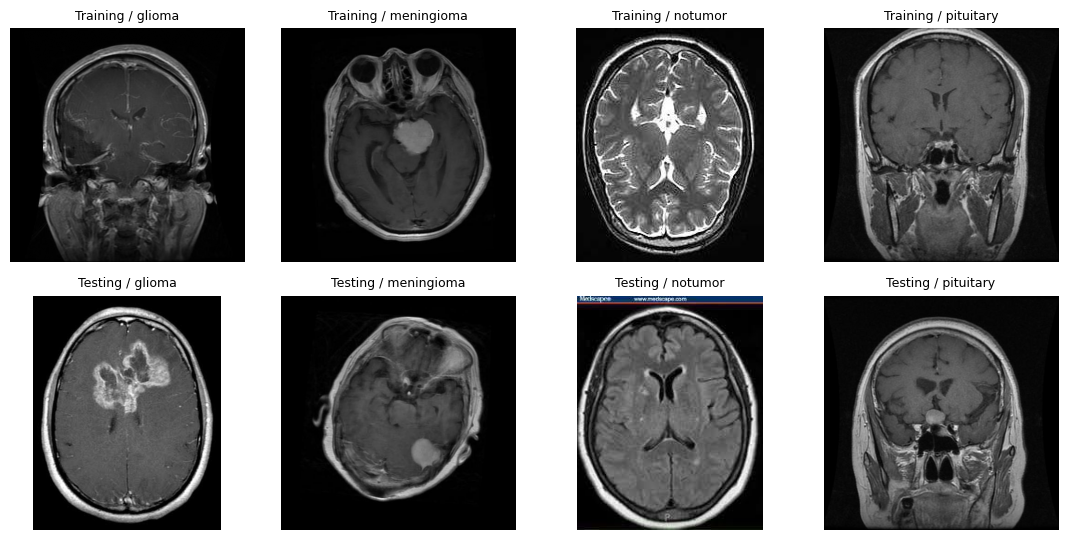

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
axes = axes.ravel()
i = 0

for split_name in ["Training", "Testing"]:
    for folder in ["glioma", "meningioma", "notumor", "pituitary"]:
        img_path = next((data_dir / split_name / folder).glob("*.jpg"))
        axes[i].imshow(Image.open(img_path), cmap="gray")
        axes[i].set_title(split_name + " / " + folder, fontsize=9)
        axes[i].axis("off")
        i += 1

plt.tight_layout()
plt.show()

## data card

- Dataset: Brain Tumor MRI Dataset, Masoud Nickparvar, Kaggle.
- Files: JPEG slices under `data/Training` and `data/Testing`.
- Original folders are tumor types. For MedShield they are all real source images.
- The Kaggle Training/Testing split is not our real/fake split. We split again before making modified copies.
- Not a diagnosis dataset and not a medical device.
